In [4]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('rossmann-store-sales')

print("Path to competition files:", path)

c:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UnauthenticatedError: User is not authenticated

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/rossmann_train.csv")

print(train.shape)
train.head()

(1017209, 9)


C:\Users\pritd\AppData\Local\Temp\ipykernel_17404\834032425.py:5: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/rossmann_train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [12]:
import os
print(os.getcwd())

c:\Users\pritd\Desktop\LTM\Incremental Proj\notebooks


In [13]:
train["Date"] = pd.to_datetime(train["Date"])

train = train.sort_values(["Store", "Date"])

print(train.dtypes)
print(train.isnull().sum())

Store                     int64
DayOfWeek                 int64
Date             datetime64[ns]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
dtype: object
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64


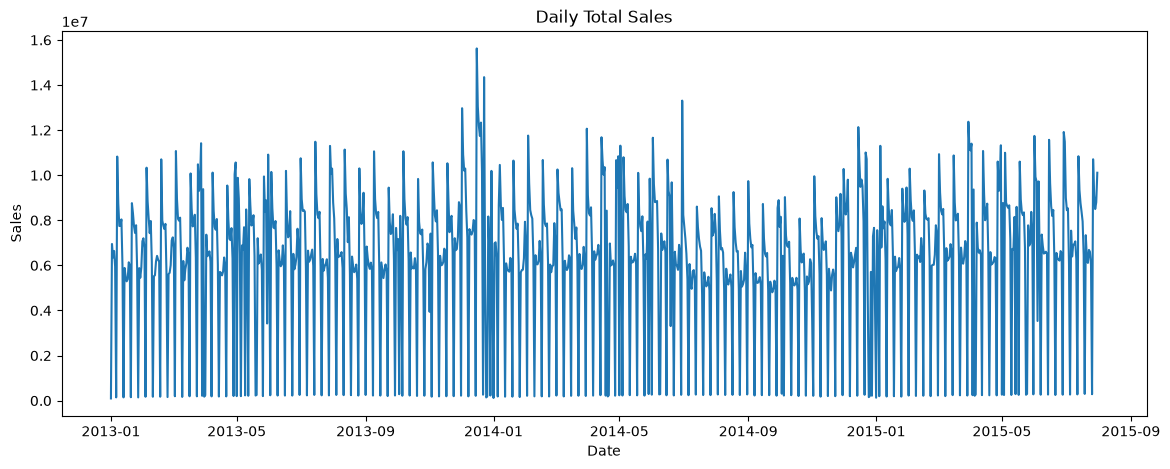

In [14]:
daily_sales = train.groupby("Date")["Sales"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales)
plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

sales_scaled = scaler.fit_transform(
    daily_sales.values.reshape(-1, 1)
)

print(sales_scaled.shape)

(942, 1)


In [16]:
X = []
y = []

for i in range(7, len(sales_scaled)):
    X.append(sales_scaled[i-7:i])
    y.append(sales_scaled[i])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (935, 7, 1)
y shape: (935, 1)


In [17]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (748, 7, 1)
X_test: (187, 7, 1)
y_train: (748, 1)
y_test: (187, 1)


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(64, activation="tanh", input_shape=(7, 1)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

C:\Users\pritd\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0760 - val_loss: 0.0488
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0435 - val_loss: 0.0439
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0415 - val_loss: 0.0437
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0415 - val_loss: 0.0446
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0412 - val_loss: 0.0435
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0405 - val_loss: 0.0430
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0406 - val_loss: 0.0440
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0401 - val_loss: 0.0429
Epoch 9/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0395 - val_loss: 0.0428
Epoch 10/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0402 - val_loss: 0.0441
Epoch 11/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0411 - val_loss: 0.0436
Epoch 12/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0419 - val_

In [20]:
test_loss = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0469
Test Loss: 0.04686461016535759


In [21]:
test_loss = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0469
Test Loss: 0.04686461016535759


In [22]:
predictions = model.predict(X_test)

predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y_test)

print("Predictions:", predictions[:10].flatten())
print("Actual:", actual[:10].flatten())

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 192ms/step
Predictions: [5657105.  5407495.  5247560.  5105752.5 4985330.  4834231.  4832134.
 5882026.5 5674440.5 5537808.5]
Actual: [ 9401803.  8392342.  7930037.  8024066.  9454954.  7354597.   225556.
 10291172.  8904680.  8136074.]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 2861889.2754010693
RMSE: 3361172.866143283


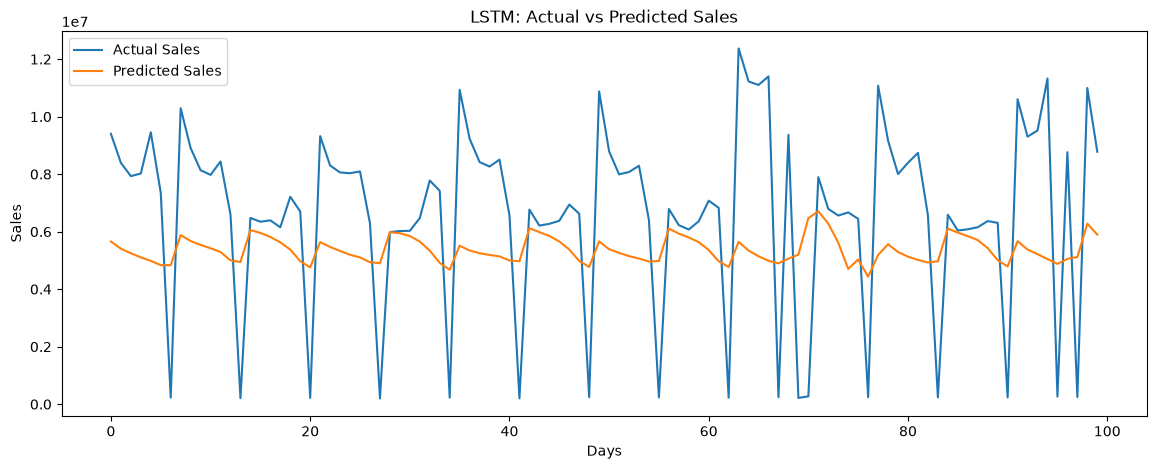

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(actual[:100], label="Actual Sales")
plt.plot(predictions[:100], label="Predicted Sales")

plt.title("LSTM: Actual vs Predicted Sales")
plt.xlabel("Days")
plt.ylabel("Sales")
plt.legend()
plt.show()

In [25]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

model.save(MODEL_DIR / "rossmann_lstm_day9.keras")

print("Model saved successfully!")



Model saved successfully!


In [26]:
import joblib

joblib.dump(scaler, MODEL_DIR / "rossmann_scaler_day9.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!
